# IPO Valuation & Listing Performance - Indian Mainboard IPOs (Aug-Dec 2025)

**Question:** Does subscription demand (QIB / NII / Retail) and issue size explain listing-day returns, and does the day-1 pop last?

**Data:** 57 mainboard IPOs, source Trendlyne IPO screener (pulled Nov 2026). REIT/InvIT listings excluded.
**Tools:** Python (pandas, statsmodels, matplotlib), SQL (SQLite), Excel (separate workbook `IPO_Analysis.xlsx`).

**Limitations (read first):** one half-year sample, P/E / P/B multiples not available in the source, and 'return till date' is a snapshot with different holding periods per IPO.

In [13]:
import sqlite3, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
import os; os.makedirs('charts', exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})

df = pd.read_csv('ipo_data.csv', parse_dates=['listing_date'])
df['gain_open']  = (df.listing_open  / df.issue_price - 1) * 100
df['gain_close'] = (df.listing_close / df.issue_price - 1) * 100
for c in ['total_x','qib_x','nii_x','retail_x','issue_size_cr']:
    df['ln_'+c] = np.log(df[c])
print(df.shape); df.head()

(57, 18)


,company,listing_date,issue_size_cr,issue_price,qib_x,nii_x,retail_x,total_x,listing_open,listing_close,gain_till_date_pct,gain_open,gain_close,ln_total_x,ln_qib_x,ln_nii_x,ln_retail_x,ln_issue_size_cr
0,Gujarat Kidney and Super Speciality,2025-12-30,250.8,114,1.1,5.7,19.0,5.2,120.0,104.5,36.6,5.263158,-8.333333,1.648659,0.095310,1.740466,2.944439,5.524656
1,KSH International,2025-12-23,644.5,384,1.1,0.4,0.9,0.8,370.0,355.0,168.0,-3.645833,-7.552083,-0.223144,0.095310,-0.916291,-0.105361,6.468475
2,ICICI Prudential Asset Management,2025-12-19,10602.6,2165,123.9,22.0,2.5,39.2,2600.0,2585.9,40.4,20.092379,19.441109,3.668677,4.819475,3.091042,0.916291,9.268855
3,Nephrocare Health Services,2025-12-17,871.0,460,27.5,24.3,2.3,14.0,490.0,471.3,41.5,6.521739,2.456522,2.639057,3.314186,3.190476,0.832909,6.769642
4,Park Medi World,2025-12-17,920.0,162,11.5,15.2,3.2,8.1,158.8,147.9,57.8,-1.975309,-8.703704,2.091864,2.442347,2.721295,1.163151,6.824374


## 1. SQL layer (SQLite)
Same data loaded into SQLite; the 6 queries live in `ipo_queries.sql`.

In [14]:
con = sqlite3.connect(':memory:')
pd.read_csv('ipo_data.csv').to_sql('ipo', con, index=False)
sql = open('ipo_queries.sql').read()
stmts = [s.strip() for s in sql.split(';') if s.strip()]
for s in stmts:
    body = "\n".join(l for l in s.splitlines() if not l.strip().startswith('--')).strip()
    if not body: continue
    if body.upper().startswith(('DROP','CREATE')):
        con.execute(body); continue
    print([l for l in s.splitlines() if l.strip().startswith('--')][0])
    print(pd.read_sql(body, con).to_string(index=False)); print()

-- Q1. Month-wise: IPO count, avg listing-day gain, avg return till date
listing_month  n_ipos  avg_listing_gain_pct  avg_till_date_pct
      2025-08      16                  15.0               37.2
      2025-09      17                   4.2                5.2
      2025-10       2                   6.1               10.1
      2025-11      12                  11.5               25.0
      2025-12      10                  10.9               71.0

-- Q2. Subscription bucket vs listing gain
sub_bucket  n_ipos  avg_listing_gain_pct  pct_positive_listing  avg_till_date_pct
   1. <10x      19                  -0.1                  42.0               17.3
 2. 10-50x      13                   5.4                  69.0                7.9
3. 50-100x      18                  12.3                  83.0               31.2
  4. 100x+       7                  40.3                 100.0              103.1

-- Q3. Issue-size bucket vs performance
   size_bucket  n_ipos  avg_listing_gain_pct  avg_subs

## 2. Descriptive stats - underpricing

In [15]:
print(df.gain_close.describe().round(1))
print('\n% closing above issue price:', round((df.gain_close>0).mean()*100,1))
print('Mean vs zero (t-test):', stats.ttest_1samp(df.gain_close, 0))
print('Return till date  mean / median:', round(df.gain_till_date_pct.mean(),1), '/', round(df.gain_till_date_pct.median(),1))

count    57.0
mean     10.0
std      19.3
min     -16.4
25%      -1.8
50%       5.0
75%      15.3
max      72.6
Name: gain_close, dtype: float64

% closing above issue price: 68.4
Mean vs zero (t-test): TtestResult(statistic=np.float64(3.921133103183566), pvalue=np.float64(0.0002427580928323647), df=np.int64(56))
Return till date  mean / median: 30.1 / 2.1


## 3. Does subscription demand explain listing gains?

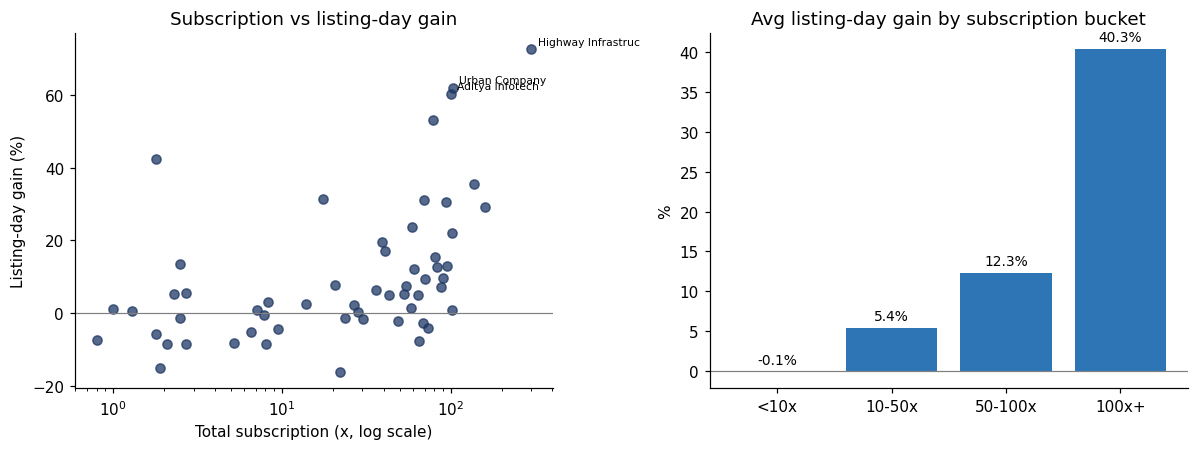

Spearman (total sub vs listing gain): SignificanceResult(statistic=np.float64(0.5732713225267726), pvalue=np.float64(3.1498711097792117e-06))
Spearman (total sub vs return till date): SignificanceResult(statistic=np.float64(0.1441952421837277), pvalue=np.float64(0.28455795416178276))


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11,4.2))
ax[0].scatter(df.total_x, df.gain_close, alpha=.75, color='#1F3864'); ax[0].set_xscale('log')
ax[0].axhline(0, color='grey', lw=.8); ax[0].set_xlabel('Total subscription (x, log scale)'); ax[0].set_ylabel('Listing-day gain (%)')
ax[0].set_title('Subscription vs listing-day gain')
for _, r in df.nlargest(3,'gain_close').iterrows(): ax[0].annotate(r.company.split(' (')[0][:18], (r.total_x, r.gain_close), fontsize=7, xytext=(4,3), textcoords='offset points')
b = pd.cut(df.total_x, [0,10,50,100,1e9], labels=['<10x','10-50x','50-100x','100x+'])
g = df.groupby(b, observed=True).gain_close.mean()
ax[1].bar(g.index.astype(str), g.values, color='#2E75B6'); ax[1].axhline(0, color='grey', lw=.8)
ax[1].set_title('Avg listing-day gain by subscription bucket'); ax[1].set_ylabel('%')
for i,v in enumerate(g.values): ax[1].text(i, v+1, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig('charts/subscription_vs_gain.png'); plt.show()
print('Spearman (total sub vs listing gain):', stats.spearmanr(df.total_x, df.gain_close))
print('Spearman (total sub vs return till date):', stats.spearmanr(df.total_x, df.gain_till_date_pct))

## 4. Regression (OLS, robust SE)
Model A: listing gain on total subscription + issue size. Model B: split by investor category + issue size. Logs because both are right-skewed.

In [17]:
mA = smf.ols('gain_close ~ ln_total_x + ln_issue_size_cr', df).fit(cov_type='HC1')
mB = smf.ols('gain_close ~ ln_qib_x + ln_nii_x + ln_retail_x + ln_issue_size_cr', df).fit(cov_type='HC1')
for name, m in [('Model A', mA), ('Model B', mB)]:
    print(name, '| R2 =', round(m.rsquared,3), '| adj R2 =', round(m.rsquared_adj,3), '| n =', int(m.nobs))
    print(m.summary().tables[1], '\n')
print('Correlation between log QIB / NII / Retail subscription:')
print(df[['ln_qib_x','ln_nii_x','ln_retail_x']].corr().round(2))

Model A | R2 = 0.338 | adj R2 = 0.314 | n = 57
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          -49.8548     14.707     -3.390      0.001     -78.679     -21.030
ln_total_x           6.7003      1.550      4.322      0.000       3.662       9.739
ln_issue_size_cr     5.8718      2.311      2.541      0.011       1.343      10.400

Model B | R2 = 0.448 | adj R2 = 0.406 | n = 57
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          -58.8813     19.642     -2.998      0.003     -97.379     -20.384
ln_qib_x             5.7853      2.609      2.218      0.027       0.672      10.898
ln_nii_x            -6.8215      2.934     -2.325      0.020     -12.571      -1.071
ln_retail_x         11.1978      3.047      3.676      

**Reading the regression honestly:** subscription is statistically significant (Model A), but R-squared of ~0.34 means most variation in listing gains is *not* explained by demand and issue size. In Model B the NII coefficient turns negative because QIB, NII and retail subscription are correlated with each other (multicollinearity) - do not interpret each coefficient in isolation; read Model B as 'investor-category demand together adds explanatory power' (R-squared ~0.45).

## 5. Does the day-1 pop last?

                        n  avg_till_date  median_till_date  pct_in_profit
day1                                                                     
Closed above issue     39           49.9              27.7           64.1
Closed at/below issue  18          -12.8             -29.8           22.2


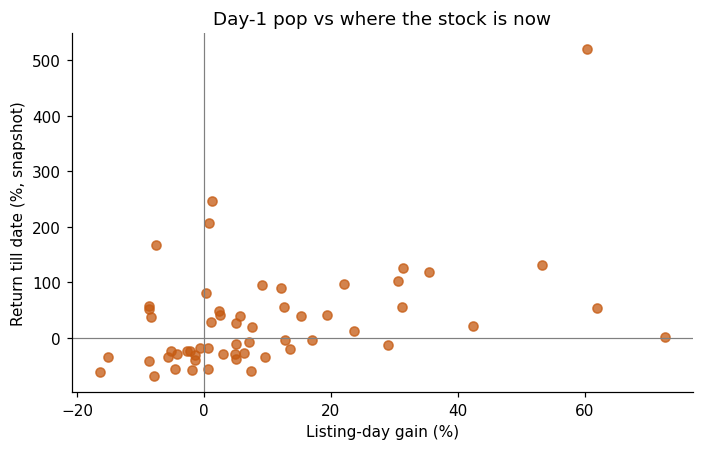

Spearman (listing gain vs till-date return): SignificanceResult(statistic=np.float64(0.4653627392810115), pvalue=np.float64(0.00026476629675508025))


In [18]:
df['day1'] = np.where(df.gain_close>0, 'Closed above issue', 'Closed at/below issue')
t = df.groupby('day1').agg(n=('company','count'), avg_till_date=('gain_till_date_pct','mean'),
                           median_till_date=('gain_till_date_pct','median'),
                           pct_in_profit=('gain_till_date_pct', lambda x: (x>0).mean()*100)).round(1)
print(t)
fig, ax = plt.subplots(figsize=(6.5,4.2))
ax.scatter(df.gain_close, df.gain_till_date_pct, alpha=.75, color='#C55A11')
ax.axhline(0, color='grey', lw=.8); ax.axvline(0, color='grey', lw=.8)
ax.set_xlabel('Listing-day gain (%)'); ax.set_ylabel('Return till date (%, snapshot)'); ax.set_title('Day-1 pop vs where the stock is now')
plt.tight_layout(); plt.savefig('charts/pop_vs_till_date.png'); plt.show()
print('Spearman (listing gain vs till-date return):', stats.spearmanr(df.gain_close, df.gain_till_date_pct))

## 6. Key findings (numbers from this notebook)

1. **Underpricing exists in this sample:** average listing-day gain ~10.0% (median 5.0%); 68% of IPOs closed above issue price on day 1.
2. **Demand lines up with the pop:** ~0% average gain for <10x issues vs ~40% for 100x+ issues (all 7 of the 100x+ IPOs closed above issue). Spearman rho ~0.57 (p < 0.001).
3. **Demand does not predict what happens next:** subscription vs return till date has a weak, insignificant rank correlation (~0.14, p ~ 0.28).
4. **Day-1 winners did better later on average (+50% vs -13%)**, but the snapshot has unequal holding periods and is skewed by outliers (Aditya Infotech ~ +519%); the median return till date for the whole sample is only ~2%.
5. **Bigger issues listed with higher average gains** (1500+ Cr: ~19% vs <500 Cr: ~5%) while getting lower subscription multiples.

**What this does not show:** causation, valuation effects (no P/E data), or anything beyond Aug-Dec 2025.

## 7. Extensions
- Add P/E and P/B at issue price from the RHP for the 15-20 largest IPOs and test whether higher P/E IPOs underperform.
- Replace the snapshot with fixed 1M / 6M returns via `yfinance` and abnormal returns vs Nifty 50.
- Extend the sample to 2023-2024 to cover different market regimes.